# HW4 – Theo Basseras: Backtester

## Imports and data loads from the notebook

We reuse the imports and data loading provided by the Lecture 8 notebook `1_backtesting.ipynb`.

## How to run this notebook

Open `hw4.ipynb` in VS Code and select a Python kernel with the course
dependencies installed, including numpy, pandas, matplotlib, scikit-learn
and duckdb.

Keep the notebook inside the course repository. It imports the teacher's
data-loading and preprocessing functions from `Lectures/modeling/`.

The notebook expects the course databases to be available in
`Lectures/modeling/data/`:
- `equities_class.duckdb` for the first examples and model development.
- `equities_top2000.duckdb` for the full homework experiment.

Restart the kernel, then select **Run All** to execute the cells from top
to bottom. Later cells use functions and variables defined earlier.

The first part checks the trade accounting and develops the strategy.
The second part trains the chosen model on the full development dataset
and evaluates it from April 1, 2016 to September 30, 2026.

The full-dataset calculations may take several minutes. Progress messages
appear during feature and target preparation.

The final cells display the comparison with the S&P 500, the performance
metrics and the missing-price diagnostics. Our strategy's final performance
remains provisional because some positions are valued using old prices.

The database files are not included in the submission.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
course_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
modeling_dir = course_root / 'Lectures/modeling'
if str(modeling_dir) not in sys.path:
    sys.path.insert(0, str(modeling_dir))

from course_data import load_data, load_membership
# Pick up changes to the shared framework when rerunning this cell.
import importlib
import backtest
importlib.reload(backtest)

from backtest import (Strategy, MonthlyTopNStrategy, MomentumStrategy, CappedMomentumStrategy,
                      OrderManagementSystem, Backtester, BacktestAnalytics)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

In [2]:
prices, fundamentals, universe, benchmark = load_data()
calendar = pd.DatetimeIndex(benchmark.date)
membership = load_membership()
display(membership.loc[membership.quarter_start.eq('2013-01-01'),
                       ['symbol', 'selection_date', 'universe_rank']].head())

display(prices.loc[prices.date.eq('2013-01-01'), ['symbol', 'date', 'close']].head())

,symbol,selection_date,universe_rank
589,APDN,2012-12-31,1
590,BKNG,2012-12-31,3
591,AAPL,2012-12-31,4
592,XOM,2012-12-31,5
593,PEGY,2012-12-31,6


,symbol,date,close


We first implement one trade

In [3]:
signal_date = pd.Timestamp('2012-12-31')
entry_date = calendar[calendar.searchsorted(signal_date, side='right')]
due_date = entry_date + pd.Timedelta(days=90)
exit_date = calendar[calendar.searchsorted(due_date, side='left')]

aapl = prices.loc[prices.symbol.eq('AAPL')].set_index('date').adj_close.sort_index()
entry_price, exit_price = aapl.loc[entry_date], aapl.loc[exit_date]

print(f'Entry date: {entry_date.date()}, entry price: {entry_price:.2f}')
print(f'Exit date: {exit_date.date()}, exit price: {exit_price:.2f}')

Entry date: 2013-01-02, entry price: 16.58
Exit date: 2013-04-02, exit price: 13.05


In [4]:
initial_cash = 1_000_000
budget = 40_000
fee_rate = 5 / 10_000
symbol = 'AAPL'

units = budget / (entry_price*(1+fee_rate))




asset_value = units * exit_price

remaining_cash = initial_cash - budget


sell_fee = asset_value * fee_rate
final_cash = remaining_cash + asset_value - sell_fee
final_pnl = final_cash - initial_cash


print(f'Units purchased: {units:.0f}')

print(f'final_pnl = {final_pnl:.2f}')


#check trade with the account object

account = OrderManagementSystem(initial_cash=initial_cash, fee_bps=fee_rate*10_000)
units = account.size_for_budget(budget=budget, price=entry_price)
lot_id = account.buy(size=units, price=entry_price, symbol='AAPL',
                     date=entry_date, signal_date=signal_date)
account.sell(size=units, price=exit_price, lot_id=lot_id, date=exit_date)

entry_pnl = account.pnl({})
display(entry_pnl)

Units purchased: 2411
final_pnl = -8547.75


cash              991452.247338
holdings_value         0.000000
nav               991452.247338
realized_pnl       -8547.752662
unrealized_pnl         0.000000
total_pnl          -8547.752662
total_fees            35.723996
dtype: float64

Our computation of the PnL is consistent with the one done  by the teacher so we can create a function from it.

In [5]:
def simulate_trade(initial_cash, budget, entry_price, exit_price, fee_rate):
    units = budget / (entry_price*(1+fee_rate))

    buy_fee = units * entry_price * fee_rate


    asset_value = units * exit_price

    remaining_cash = initial_cash - budget


    sell_fee = asset_value * fee_rate

    total_fees = buy_fee + sell_fee
    final_cash = remaining_cash + asset_value - sell_fee
    final_pnl = final_cash - initial_cash

    return units, total_fees, final_cash, final_pnl

#Let's decompose the simulate_trade function into two functions, one for buying and one for selling.

def buy(cash, budget, entry_price, fee_rate):
    if budget <= 0 or budget > cash:
        raise ValueError("Budget must be positive and cannot exceed cash.")
    units = budget / (entry_price*(1+fee_rate))
    buy_fee = units * entry_price * fee_rate
    remaining_cash = cash - budget

    return units, buy_fee, remaining_cash

def sell(units, exit_price, remaining_cash, fee_rate):
    asset_value = units * exit_price
    sell_fee = asset_value * fee_rate
    final_cash = remaining_cash + asset_value - sell_fee

    return final_cash, sell_fee

# Small test
units, buy_fee, cash = buy(initial_cash, budget, entry_price, fee_rate)
cash, sell_fee = sell(units, exit_price, cash, fee_rate)

print(cash - initial_cash)

-8547.752661666716


Now we want to register our assets into a portfolio, for that we will use a dictionary

In [6]:


units, buy_fee, remaining_cash = buy(initial_cash, budget, entry_price, fee_rate)

current_date=pd.Timestamp('2013-02-01')
current_date_market = calendar[calendar.searchsorted(current_date, side='left')]
current_price = prices.loc[(prices.symbol == symbol) & (prices.date == current_date_market), 'adj_close'].values[0]
holdings_value = units * current_price
nav = remaining_cash + holdings_value

print(f'Current date: {current_date_market.date()}, current price: {current_price:.2f}, NAV: {nav:.2f}')
lot={ 'symbol': symbol, 'units': units, 'entry_price': entry_price, 'entry_date': entry_date, 'due_date': due_date, 'buy_fee': buy_fee}

display(lot)

# for each date in the calendar, we will compute the NAV of the account and store it in a list. We will also store the current price of the asset and the holdings value.
navs = []

for current_date in calendar[(calendar >= entry_date) & (calendar <= exit_date)]:
    if current_date == exit_date:
        sell_price = prices.loc[(prices.symbol == symbol) & (prices.date == current_date), 'adj_close'].values[0]
        final_cash, sell_fee = sell(units, sell_price, remaining_cash, fee_rate)
        nav = final_cash
        navs.append({'date': current_date, 'nav': nav, 'current_price': sell_price, 'holdings_value': 0, 'remaining_cash': final_cash})
    else:
        current_price = prices.loc[(prices.symbol == symbol) & (prices.date == current_date), 'adj_close'].values[0]
        holdings_value = units * current_price
        nav = remaining_cash + holdings_value
        navs.append({'date': current_date, 'nav': nav, 'current_price': current_price, 'holdings_value': holdings_value, 'remaining_cash': remaining_cash})


navs_df = pd.DataFrame(navs).set_index('date')
display(navs_df)


# Let's check that the NAV is equal to the remaining cash plus the holdings value for each date, and that the remaining cash is always non-negative. We will also check that the final NAV is equal to the final cash after selling the asset.

assert np.allclose(navs_df["nav"], navs_df["remaining_cash"] + navs_df["holdings_value"])
assert (navs_df["remaining_cash"] >= 0).all()
assert np.isclose(navs_df.iloc[-1]["nav"], 991452.247338)

Current date: 2013-02-01, current price: 13.70, NAV: 993035.35


{'symbol': 'AAPL',
 'units': np.float64(2411.3395654404408),
 'entry_price': np.float64(16.58),
 'entry_date': Timestamp('2013-01-02 00:00:00'),
 'due_date': Timestamp('2013-04-02 00:00:00'),
 'buy_fee': np.float64(19.990004997501252)}

,nav,current_price,holdings_value,remaining_cash
date,,,,
2013-01-02,999980.009995,16.58,39980.009995,960000.000000
2013-01-03,999473.628686,16.37,39473.628686,960000.000000
2013-01-04,998388.525882,15.92,38388.525882,960000.000000
2013-01-07,998147.391925,15.82,38147.391925,960000.000000
2013-01-08,998243.845508,15.86,38243.845508,960000.000000
...,...,...,...,...
2013-03-26,993758.753916,14.00,33758.753916,960000.000000
2013-03-27,993107.692233,13.73,33107.692233,960000.000000
2013-03-28,992408.403760,13.44,32408.403760,960000.000000


Now we generalize this function, to create a backtest on this one trade

In [7]:
def backtest_one_trade(prices, calendar, symbol, signal_date,
                       initial_cash, budget, fee_rate):

    #We check that we have enough cash
    if budget <= 0 or budget > initial_cash:
        raise ValueError("Budget must be positive and cannot exceed initial cash.")

    prices_symbol = prices.loc[prices.symbol.eq(symbol)].set_index('date').adj_close.sort_index()

    #We keep only valid prices
    prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)]

    if calendar.searchsorted(signal_date, side='right') >= len(calendar):
        raise ValueError("No entry date available.")

    entry_date = calendar[calendar.searchsorted(signal_date, side='right')]

    #We move to the next date if there is no price
    while entry_date not in prices_symbol.index:
        if calendar.searchsorted(entry_date) + 1 >= len(calendar):
            raise ValueError("No buying price available before the calendar ends.")

        entry_date = calendar[calendar.searchsorted(entry_date) + 1]

    due_date = entry_date + pd.Timedelta(days=90)

    if calendar.searchsorted(due_date, side='left') >= len(calendar):
        raise ValueError("Exit date is out of bounds.")

    exit_date = calendar[calendar.searchsorted(due_date, side='left')]

    #We do the same for the selling date
    while exit_date not in prices_symbol.index:
        if calendar.searchsorted(exit_date) + 1 >= len(calendar):
            raise ValueError("No selling price available before the calendar ends.")

        exit_date = calendar[calendar.searchsorted(exit_date) + 1]

    units, buy_fee, remaining_cash = buy(initial_cash, budget, prices_symbol.loc[entry_date], fee_rate)

    current_price = prices_symbol.loc[entry_date]
    navs = []

    for current_date in calendar[(calendar >= entry_date) & (calendar <= exit_date)]:
        if current_date == exit_date:
            sell_price = prices_symbol.loc[current_date]
            final_cash, sell_fee = sell(units, sell_price, remaining_cash, fee_rate)
            nav = final_cash
            navs.append({'date': current_date, 'nav': nav, 'current_price': sell_price, 'holdings_value': 0, 'remaining_cash': final_cash})

        else:
            if current_date in prices_symbol.index:
                current_price = prices_symbol.loc[current_date]
            #Otherwise we keep the last known price

            holdings_value = units * current_price
            nav = remaining_cash + holdings_value
            navs.append({'date': current_date, 'nav': nav, 'current_price': current_price, 'holdings_value': holdings_value, 'remaining_cash': remaining_cash})

    history = pd.DataFrame(navs).set_index('date')

    return history

#We test the backtest_one_trade function with the same parameters as before and check that the final NAV is equal to the final cash after selling the asset.

history = backtest_one_trade(prices, calendar, symbol, signal_date, initial_cash, budget, fee_rate)

display(history)

,nav,current_price,holdings_value,remaining_cash
date,,,,
2013-01-02,999980.009995,16.58,39980.009995,960000.000000
2013-01-03,999473.628686,16.37,39473.628686,960000.000000
2013-01-04,998388.525882,15.92,38388.525882,960000.000000
2013-01-07,998147.391925,15.82,38147.391925,960000.000000
2013-01-08,998243.845508,15.86,38243.845508,960000.000000
...,...,...,...,...
2013-03-26,993758.753916,14.00,33758.753916,960000.000000
2013-03-27,993107.692233,13.73,33107.692233,960000.000000
2013-03-28,992408.403760,13.44,32408.403760,960000.000000


Now let's try to handle multiple stocks.

In [8]:
symbol_1='AAPL'
symbol_2='MSFT'

lots = []

budget_1 = 40_000
budget_2 = 60_000

units_1, buy_fee_1, remaining_cash_1 = buy(initial_cash, budget_1, prices.loc[(prices.symbol == symbol_1) & (prices.date == entry_date), 'adj_close'].values[0], fee_rate)

print(f'Remaining cash after buying {symbol_1}: {remaining_cash_1:.2f}')

units_2, buy_fee_2, remaining_cash_2 = buy(remaining_cash_1, budget_2, prices.loc[(prices.symbol == symbol_2) & (prices.date == entry_date), 'adj_close'].values[0], fee_rate)

lots.append({'symbol': symbol_1, 'units': units_1, 'entry_price': prices.loc[(prices.symbol == symbol_1) & (prices.date == entry_date), 'adj_close'].values[0], 'entry_date': entry_date, 'due_date': due_date, 'buy_fee': buy_fee_1})
lots.append({'symbol': symbol_2, 'units': units_2, 'entry_price': prices.loc[(prices.symbol == symbol_2) & (prices.date == entry_date), 'adj_close'].values[0], 'entry_date': entry_date, 'due_date': due_date, 'buy_fee': buy_fee_2})

display(pd.DataFrame(lots))
print(f'Remaining cash after buying both lots: {remaining_cash_2:.2f}')

total_holdings_value = units_1 * prices.loc[(prices.symbol == symbol_1) & (prices.date == exit_date), 'adj_close'].values[0] + \
                       units_2 * prices.loc[(prices.symbol == symbol_2) & (prices.date == exit_date), 'adj_close'].values[0]

nav = remaining_cash_2 + total_holdings_value


print(f'NAV before selling: {nav:.2f}')

#We repeat the calculation of the NAV for each date in the calendar, taking into account both lots. We will also store the current price of each asset and the holdings value for each lot.


#We copy the lots so we keep the original list
open_lots = [lot.copy() for lot in lots]

#We find the selling date for each lot
for lot in open_lots:
    prices_symbol = prices.loc[prices.symbol.eq(lot['symbol'])].set_index('date').adj_close.sort_index()
    prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)]

    if calendar.searchsorted(lot['due_date'], side='left') >= len(calendar):
        raise ValueError("Exit date is out of bounds.")

    exit_date = calendar[calendar.searchsorted(lot['due_date'], side='left')]

    #We move to the next date if there is no price
    while exit_date not in prices_symbol.index:
        if calendar.searchsorted(exit_date) + 1 >= len(calendar):
            raise ValueError(f"No selling price available for {lot['symbol']} before the calendar ends.")

        exit_date = calendar[calendar.searchsorted(exit_date) + 1]

    lot['exit_date'] = exit_date

cash = remaining_cash_2
start_date = min(lot['entry_date'] for lot in open_lots)
end_date = max(lot['exit_date'] for lot in open_lots)

navs = []

#We compute the value of the portfolio each day
for current_date in calendar[(calendar >= start_date) & (calendar <= end_date)]:
    total_holdings_value = 0
    sell_fees = 0

    #We loop over a copy so we can remove the lots we sell
    for lot in open_lots.copy():
        prices_symbol = prices.loc[prices.symbol.eq(lot['symbol'])].set_index('date').adj_close.sort_index()
        prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)]

        if current_date == lot['exit_date']:
            sell_price = prices_symbol.loc[current_date]
            cash, sell_fee = sell(lot['units'], sell_price, cash, fee_rate)

            sell_fees += sell_fee
            open_lots.remove(lot)

        else:
            #We keep the last available price if today's price is missing
            current_price = prices_symbol.loc[:current_date].iloc[-1]
            holdings_value = lot['units'] * current_price
            total_holdings_value += holdings_value

    nav = cash + total_holdings_value

    navs.append({'date': current_date, 'nav': nav,
                 'holdings_value': total_holdings_value, 'remaining_cash': cash,
                 'sell_fees': sell_fees, 'open_lots': len(open_lots)})

history = pd.DataFrame(navs).set_index('date')
display(history)

Remaining cash after buying AAPL: 960000.00


,symbol,units,entry_price,entry_date,due_date,buy_fee
0,AAPL,2411.339565,16.58,2013-01-02,2013-04-02,19.990005
1,MSFT,2707.449887,22.15,2013-01-02,2013-04-02,29.985007


Remaining cash after buying both lots: 900000.00
NAV before selling: 994524.49


,nav,holdings_value,remaining_cash,sell_fees,open_lots
date,,,,,
2013-01-02,999950.024988,99950.024988,900000.000000,0.000000,2
2013-01-03,998631.408713,98631.408713,900000.000000,0.000000,2
2013-01-04,996436.251455,96436.251455,900000.000000,0.000000,2
2013-01-07,996086.819503,96086.819503,900000.000000,0.000000,2
2013-01-08,995885.453598,95885.453598,900000.000000,0.000000,2
...,...,...,...,...,...
2013-03-26,995407.387838,95407.387838,900000.000000,0.000000,2
2013-03-27,995216.592637,95216.592637,900000.000000,0.000000,2
2013-03-28,995058.794140,95058.794140,900000.000000,0.000000,2


In [9]:
#We take the last trading day of each month
signal_dates = []

for i in range(len(calendar) - 1):
    current_date = calendar[i]
    next_date = calendar[i + 1]

    #If the next trading day is in another month, this is the last one
    if current_date.month != next_date.month:
        if pd.Timestamp('2012-12-01') <= current_date <= pd.Timestamp('2013-11-30'):
            signal_dates.append(current_date)

display(signal_dates)

#We take these last days of month as buying dates

#We buy on the trading day after each signal
buy_dates = []

for signal_date in signal_dates:
    entry_date = calendar[calendar.searchsorted(signal_date, side='right')]
    buy_dates.append(entry_date)

print(buy_dates)

[Timestamp('2012-12-31 00:00:00'),
 Timestamp('2013-01-31 00:00:00'),
 Timestamp('2013-02-28 00:00:00'),
 Timestamp('2013-03-28 00:00:00'),
 Timestamp('2013-04-30 00:00:00'),
 Timestamp('2013-05-31 00:00:00'),
 Timestamp('2013-06-28 00:00:00'),
 Timestamp('2013-07-31 00:00:00'),
 Timestamp('2013-08-30 00:00:00'),
 Timestamp('2013-09-30 00:00:00'),
 Timestamp('2013-10-31 00:00:00'),
 Timestamp('2013-11-29 00:00:00')]

[Timestamp('2013-01-02 00:00:00'), Timestamp('2013-02-01 00:00:00'), Timestamp('2013-03-01 00:00:00'), Timestamp('2013-04-01 00:00:00'), Timestamp('2013-05-01 00:00:00'), Timestamp('2013-06-03 00:00:00'), Timestamp('2013-07-01 00:00:00'), Timestamp('2013-08-01 00:00:00'), Timestamp('2013-09-03 00:00:00'), Timestamp('2013-10-01 00:00:00'), Timestamp('2013-11-01 00:00:00'), Timestamp('2013-12-02 00:00:00')]


Now we do a yearly simulation

In [10]:
def backtest_portfolio(prices, calendar, signal_dates, symbols, initial_cash, budget, fee_rate, start_date, end_date):

    if budget <= 0 or budget > initial_cash:
        raise ValueError("Budget must be positive and cannot exceed initial cash.")

    cash = initial_cash
    lots = []
    pending_buys = []
    navs = []

    #We store the prices of each stock
    prices_by_symbol = {}

    for symbol in symbols:
        prices_symbol = prices.loc[prices.symbol.eq(symbol)].set_index('date').adj_close.sort_index()
        prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)]
        prices_by_symbol[symbol] = prices_symbol

    #We find the buying date after each signal
    buy_dates = {}

    for signal_date in signal_dates:
        if calendar.searchsorted(signal_date, side='right') >= len(calendar):
            raise ValueError("No entry date available.")

        entry_date = calendar[calendar.searchsorted(signal_date, side='right')]
        buy_dates[entry_date] = signal_date

    for current_date in calendar[(calendar >= start_date) & (calendar <= end_date)]:
        buy_fees = 0
        sell_fees = 0
        stale_marks = 0

        #We add the purchases planned for today
        if current_date in buy_dates:
            for symbol in symbols:
                pending_buys.append({'symbol': symbol, 'signal_date': buy_dates[current_date]})

        #We buy before selling so today's sales fund later purchases
        for order in pending_buys.copy():
            symbol = order['symbol']
            prices_symbol = prices_by_symbol[symbol]

            #If there is no price we wait for another day
            if current_date not in prices_symbol.index:
                continue

            #If we do not have enough cash we skip this purchase
            if cash < budget:
                pending_buys.remove(order)
                continue

            entry_price = prices_symbol.loc[current_date]
            units, buy_fee, cash = buy(cash, budget, entry_price, fee_rate)

            lots.append({'symbol': symbol, 'signal_date': order['signal_date'], 'units': units, 'entry_price': entry_price, 'entry_date': current_date, 'due_date': current_date + pd.Timedelta(days=90), 'buy_fee': buy_fee, 'current_price': entry_price})

            buy_fees += buy_fee
            pending_buys.remove(order)

        #We sell the lots that have reached their due date
        for lot in lots.copy():
            prices_symbol = prices_by_symbol[lot['symbol']]

            if current_date >= lot['due_date']:
                #If there is no price we try again the next day
                if current_date not in prices_symbol.index:
                    continue

                sell_price = prices_symbol.loc[current_date]
                cash, sell_fee = sell(lot['units'], sell_price, cash, fee_rate)

                sell_fees += sell_fee
                lots.remove(lot)

        #We compute the value of the lots we still own
        total_holdings_value = 0

        for lot in lots:
            prices_symbol = prices_by_symbol[lot['symbol']]

            if current_date in prices_symbol.index:
                lot['current_price'] = prices_symbol.loc[current_date]
            else:
                #Otherwise we keep the last known price
                stale_marks += 1

            holdings_value = lot['units'] * lot['current_price']
            total_holdings_value += holdings_value

        nav = cash + total_holdings_value
        navs.append({'date': current_date, 'nav': nav, 'holdings_value': total_holdings_value, 'remaining_cash': cash, 'buy_fees': buy_fees, 'sell_fees': sell_fees, 'open_lots': len(lots), 'stale_marks': stale_marks})

    history = pd.DataFrame(navs).set_index('date')

    return history, lots

history, lots = backtest_portfolio(prices, calendar, signal_dates, ['AAPL', 'MSFT'], initial_cash=1_000_000, budget=40_000, fee_rate=5 / 10_000, start_date=pd.Timestamp('2013-01-01'), end_date=pd.Timestamp('2013-12-31'))

display(history)
display(pd.DataFrame(lots))

,nav,holdings_value,remaining_cash,buy_fees,sell_fees,open_lots,stale_marks
date,,,,,,,
2013-01-02,9.999600e+05,79960.019990,920000.000000,39.98001,0.000000,2,0
2013-01-03,9.989121e+05,78912.148704,920000.000000,0.00000,0.000000,2,0
2013-01-04,9.970870e+05,77087.009597,920000.000000,0.00000,0.000000,2,0
2013-01-07,9.967737e+05,76773.676977,920000.000000,0.00000,0.000000,2,0
2013-01-08,9.966716e+05,76671.584234,920000.000000,0.00000,0.000000,2,0
...,...,...,...,...,...,...,...
2013-12-24,1.068623e+06,256909.332950,811713.739736,0.00000,0.000000,6,0
2013-12-26,1.069023e+06,257308.881858,811713.739736,0.00000,0.000000,6,0
2013-12-27,1.067633e+06,255919.107422,811713.739736,0.00000,0.000000,6,0


,symbol,signal_date,units,entry_price,entry_date,due_date,buy_fee,current_price
0,AAPL,2013-10-31,2497.189881,16.01,2013-11-01,2014-01-30,19.990005,17.38
1,MSFT,2013-10-31,1371.997598,29.14,2013-11-01,2014-01-30,19.990005,30.92
2,AAPL,2013-11-29,2340.750000,17.08,2013-12-02,2014-03-02,19.990005,17.38
3,MSFT,2013-11-29,1258.024229,31.78,2013-12-02,2014-03-02,19.990005,30.92


In [11]:
#We reuse the teacher's function to compute the features
from course_data import price_features

panel = price_features(prices, calendar)

features = ['momentum_63', 'volatility_63']

display(panel)

display(panel.loc[panel.symbol.eq('AAPL') & panel.date.ge('2013-01-01'), ['date', 'symbol'] + features].head())

,date,symbol,close,adj_close,volume,momentum_21,momentum_63,momentum_252_21,volatility_63,drawdown_252,eligible
0,2008-01-02,AAPL,6.96,5.83,1.079179e+09,NaN,NaN,NaN,NaN,NaN,False
1,2008-01-02,AMT,41.24,31.49,3.144900e+06,NaN,NaN,NaN,NaN,NaN,False
2,2008-01-02,APDN,3492000.30,3492000.30,0.000000e+00,NaN,NaN,NaN,NaN,NaN,False
3,2008-01-02,BESS,369.60,369.60,2.900000e+01,NaN,NaN,NaN,NaN,NaN,False
4,2008-01-02,BKNG,115.24,114.42,1.619800e+06,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...
59281,2015-12-31,T,25.97,15.06,2.684477e+07,0.018945,0.072650,0.063309,0.148786,-0.022713,True
59282,2015-12-31,TSYS,4.97,4.97,4.136800e+05,0.010163,0.436416,0.576923,0.441609,-0.002008,True
59283,2015-12-31,UPS,96.23,71.34,2.178632e+06,-0.078056,-0.016949,-0.033837,0.159022,-0.133277,True
59284,2015-12-31,WMT,20.43,17.23,1.972544e+07,0.048054,-0.038504,-0.300128,0.265513,-0.303557,True


,date,symbol,momentum_63,volatility_63
37112,2013-01-02,AAPL,-0.173480,0.353937
37141,2013-01-03,AAPL,-0.174483,0.354065
37171,2013-01-04,AAPL,-0.199598,0.357271
37201,2013-01-07,AAPL,-0.216444,0.355358
37230,2013-01-08,AAPL,-0.208978,0.355503


Now we compute the target we would like to predict, here we choose as target the return after 90 days.

In [12]:
def compute_target(prices_symbol, calendar, signal_date):

    prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)].sort_index()

    if calendar.searchsorted(signal_date, side='right') >= len(calendar):
        return np.nan, pd.NaT

    entry_date = calendar[calendar.searchsorted(signal_date, side='right')]

    #We move to the next date if there is no price
    while entry_date not in prices_symbol.index:
        if calendar.searchsorted(entry_date) + 1 >= len(calendar):
            return np.nan, pd.NaT

        entry_date = calendar[calendar.searchsorted(entry_date) + 1]

    due_date = entry_date + pd.Timedelta(days=90)

    if calendar.searchsorted(due_date, side='left') >= len(calendar):
        return np.nan, pd.NaT

    exit_date = calendar[calendar.searchsorted(due_date, side='left')]

    #We do the same for the selling date
    while exit_date not in prices_symbol.index:
        if calendar.searchsorted(exit_date) + 1 >= len(calendar):
            return np.nan, pd.NaT

        exit_date = calendar[calendar.searchsorted(exit_date) + 1]

    target = prices_symbol.loc[exit_date] / prices_symbol.loc[entry_date] - 1

    return target, exit_date


#We test with our Apple example
prices_symbol = prices.loc[prices.symbol.eq('AAPL')].set_index('date').adj_close.sort_index()

target, label_end = compute_target(prices_symbol, calendar, pd.Timestamp('2012-12-31'))

print(f'Target: {target:.2%}')
print(f'Exit date: {label_end}')

Target: -21.29%
Exit date: 2013-04-02 00:00:00


Now let's compute this return for each stock.

In [13]:
#We add the target and the date when it becomes known
panel['target'] = np.nan
panel['label_end'] = pd.NaT

for symbol in panel['symbol'].unique():
    prices_symbol = prices.loc[prices.symbol.eq(symbol)].set_index('date').adj_close.sort_index()

    #We use the development period
    rows = panel.loc[panel.symbol.eq(symbol) & panel.date.ge('2010-01-01') & panel.date.le('2015-12-31')]

    for index, row in rows.iterrows():
        target, label_end = compute_target(prices_symbol, calendar, row['date'])

        panel.at[index, 'target'] = target
        panel.at[index, 'label_end'] = label_end

display(panel.loc[panel.symbol.eq('AAPL') & panel.date.ge('2013-01-01'), ['date', 'symbol'] + features + ['target', 'label_end']].head())

,date,symbol,momentum_63,volatility_63,target,label_end
37112,2013-01-02,AAPL,-0.173480,0.353937,-0.198534,2013-04-03
37141,2013-01-03,AAPL,-0.174483,0.354065,-0.184045,2013-04-04
37171,2013-01-04,AAPL,-0.199598,0.357271,-0.182048,2013-04-08
37201,2013-01-07,AAPL,-0.216444,0.355358,-0.184111,2013-04-08
37230,2013-01-08,AAPL,-0.208978,0.355503,-0.169654,2013-04-09


In [14]:
display(panel.loc[panel.symbol.eq('AMT') & panel.date.ge('2013-01-01'), ['date', 'symbol'] + features + ['target', 'label_end']].head())

,date,symbol,momentum_63,volatility_63,target,label_end
37113,2013-01-02,AMT,0.110890,0.175940,0.011667,2013-04-03
37142,2013-01-03,AMT,0.088534,0.183242,0.019850,2013-04-04
37172,2013-01-04,AMT,0.078625,0.182749,0.029893,2013-04-08
37202,2013-01-07,AMT,0.062456,0.180953,0.025782,2013-04-08
37231,2013-01-08,AMT,0.077806,0.179573,0.023479,2013-04-09


So we have our 90 days return for each stock. Now let's try to predict them, for that we can start by a ridge regression

In [15]:
from course_data import apply_membership
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

#We check which stocks were eligible at the time
model_data = apply_membership(panel, membership, calendar)
model_data = model_data.loc[model_data.eligible].copy()

#We keep rows with available features
model_data = model_data.dropna(subset=features)

#We train only with outcomes known before 2013
train = model_data.loc[model_data.date.ge('2010-01-01') & model_data.date.lt('2013-01-01') & model_data.label_end.lt('2013-01-01') & model_data.target.notna()].copy()

#We evaluate on 2013 without training on it
validation = model_data.loc[model_data.date.ge('2013-01-01') & model_data.date.lt('2014-01-01') & model_data.target.notna()].copy()

#We start with a simple Ridge model
model = make_pipeline(StandardScaler(), Ridge(alpha=1))
model.fit(train[features], train['target'])

validation['prediction'] = model.predict(validation[features])

display(validation[['date', 'symbol', 'target', 'prediction']].head())

,date,symbol,target,prediction
37112,2013-01-02,AAPL,-0.198534,0.077135
37113,2013-01-02,AMT,0.011667,0.014710
37114,2013-01-02,APDN,0.000000,0.159469
37115,2013-01-02,BESS,0.122449,0.211804
37116,2013-01-02,BKNG,0.077070,0.039795



The model above is a simple ridge. We can try to make it more adapted to our prediction goal. For instance we can use exponential weight and fit  the parameter of this model (we split the training dataset in two in order to get a validation dataset to get the best parameters for our model)

In [16]:
from course_data import apply_membership
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

model_data = apply_membership(panel, membership, calendar)
model_data = model_data.loc[model_data.eligible].dropna(subset=features).copy()

#We train only with outcomes known before 2013
fit_date = pd.Timestamp('2013-01-01')
train = model_data.loc[model_data.date.ge('2010-01-01') & model_data.date.lt(fit_date) & model_data.label_end.lt(fit_date) & model_data.target.notna()].copy()

#We use 2013 to choose alpha
validation = model_data.loc[model_data.date.ge('2013-01-01') & model_data.date.lt('2014-01-01') & model_data.target.notna()].copy()

print(f'Training rows: {len(train)}')
print(f'Validation rows: {len(validation)}')

Training rows: 20034
Validation rows: 7308


In [17]:
#An example 180 days older gets half as much weight
half_life = 180
age = (fit_date - train['date']).dt.days
weights = 0.5 ** (age / half_life)

#We keep the average weight equal to 1
weights = weights / weights.mean()

In [18]:
alphas = [0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]
results = []
best_mse = np.inf

for alpha in alphas:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model.fit(train[features], train['target'], standardscaler__sample_weight=weights, ridge__sample_weight=weights)

    prediction = model.predict(validation[features])
    mse = mean_squared_error(validation['target'], prediction)
    mae = mean_absolute_error(validation['target'], prediction)

    results.append({'alpha': alpha, 'MSE': mse, 'MAE': mae})

    if mse < best_mse:
        best_mse = mse
        best_alpha = alpha
        best_model = model

display(pd.DataFrame(results))

validation['prediction'] = best_model.predict(validation[features])

print(f'Best alpha: {best_alpha}')
print(f'Validation MSE: {mean_squared_error(validation["target"], validation["prediction"]):.6f}')
print(f'Validation MAE: {mean_absolute_error(validation["target"], validation["prediction"]):.6f}')

,alpha,MSE,MAE
0,0.1,0.027250,0.106781
1,1.0,0.027249,0.106780
2,10.0,0.027240,0.106761
3,100.0,0.027150,0.106576
4,1000.0,0.026337,0.104894
5,10000.0,0.022565,0.096958
6,100000.0,0.020665,0.092653
7,1000000.0,0.020848,0.092985


Best alpha: 100000


Validation MSE: 0.020665
Validation MAE: 0.092653


Now we compare our ridge prediction to a simple prediction (average return).

In [19]:
#We keep the alpha chosen using 2013
#We refit using only outcomes known before 2015
fit_date_2015 = pd.Timestamp('2015-01-01')

train_2015 = model_data.loc[model_data.date.ge('2010-01-01') & model_data.date.lt(fit_date_2015) & model_data.label_end.lt(fit_date_2015) & model_data.target.notna()].copy()

age = (fit_date_2015 - train_2015['date']).dt.days
weights_2015 = 0.5 ** (age / half_life)
weights_2015 = weights_2015 / weights_2015.mean()

model_2015 = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
model_2015.fit(train_2015[features], train_2015['target'], standardscaler__sample_weight=weights_2015, ridge__sample_weight=weights_2015)

#We predict all eligible rows in 2015
predictions_2015 = model_data.loc[model_data.date.ge('2015-01-01') & model_data.date.lt('2016-01-01')].copy()
predictions_2015['prediction'] = model_2015.predict(predictions_2015[features])

#We compare with always predicting the weighted average training return
average_return = np.average(train_2015['target'], weights=weights_2015)
predictions_2015['baseline'] = average_return

#We can measure errors only where the actual outcome is available
evaluation = predictions_2015.loc[predictions_2015.target.notna()].copy()

results_2015 = []

for name in ['prediction', 'baseline']:
    mse = mean_squared_error(evaluation['target'], evaluation[name])
    mae = mean_absolute_error(evaluation['target'], evaluation[name])

    results_2015.append({'model': name, 'MSE': mse, 'MAE': mae})

display(pd.DataFrame(results_2015))
print(f'Baseline return: {average_return:.2%}')

,model,MSE,MAE
0,prediction,0.034120,0.107973
1,baseline,0.034522,0.107970


Baseline return: 3.10%


Our ridge prediction does not yield too much improvement in terms of predictions compared to a simple predictor (constant equal to the average of returns).

But let's try to use this predictor and to build a strategy on it buying the best ranked stocks.
The idea here I propose is to buy the 10 first top ranked stocks in terms of returns and to buy them in proportion of their predicted return.

In [20]:
def allocate_cash(predictions, signal_date, cash):

    if not np.isfinite(cash) or cash < 0:
        raise ValueError("Cash must be finite and non-negative.")

    orders = predictions.loc[predictions.date.eq(signal_date), ['symbol', 'prediction']].copy()
    orders = orders.loc[np.isfinite(orders['prediction']) & (orders['prediction'] > 0)]
    orders = orders.sort_values('prediction', ascending=False).head(10)

    if orders.empty:
        orders['budget'] = pd.Series(dtype=float)
        return orders

    #We allocate the cash proportionally to the predictions
    orders['budget'] = cash * orders['prediction'] / orders['prediction'].sum()

    return orders


def backtest_model(prices, calendar, predictions, signal_dates, membership, initial_cash, fee_rate, start_date, end_date):

    if not np.isfinite(initial_cash) or initial_cash <= 0:
        raise ValueError("Initial cash must be positive.")

    if not np.isfinite(fee_rate) or fee_rate < 0:
        raise ValueError("Fee rate must be non-negative.")

    cash = initial_cash
    lots = []
    pending_buys = []
    navs = []
    trades = []
    lot_id = 0

    #We store the prices of each stock
    prices_by_symbol = {}

    for symbol in predictions['symbol'].unique():
        prices_symbol = prices.loc[prices.symbol.eq(symbol)].set_index('date').adj_close.sort_index()
        prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)]
        prices_by_symbol[symbol] = prices_symbol

    #We find the buying date after each signal
    buy_dates = {}

    for signal_date in signal_dates:
        if calendar.searchsorted(signal_date, side='right') >= len(calendar):
            raise ValueError("No entry date available.")

        entry_date = calendar[calendar.searchsorted(signal_date, side='right')]
        buy_dates[entry_date] = signal_date

    for current_date in calendar[(calendar >= start_date) & (calendar <= end_date)]:
        buy_fees = 0
        sell_fees = 0
        stale_marks = 0

        #We check which stocks are eligible for today's purchases
        quarter_start = current_date.to_period('Q').start_time
        eligible_symbols = membership.loc[membership.quarter_start.eq(quarter_start) & membership.selection_date.lt(current_date), 'symbol']

        #We do not allocate cash already reserved for another purchase
        if current_date in buy_dates:
            reserved_cash = sum(order['budget'] for order in pending_buys)
            available_cash = max(0, cash - reserved_cash)

            orders = allocate_cash(predictions, buy_dates[current_date], available_cash)
            orders = orders.loc[orders.budget > 0]

            for index, order in orders.iterrows():
                pending_buys.append({'symbol': order['symbol'], 'budget': order['budget'], 'signal_date': buy_dates[current_date]})

        #We buy before selling so today's sales fund later purchases
        for order in pending_buys.copy():
            symbol = order['symbol']
            budget = order['budget']
            prices_symbol = prices_by_symbol[symbol]

            #We check membership again if the purchase was delayed
            if symbol not in eligible_symbols.values:
                pending_buys.remove(order)
                continue

            #If there is no price we wait for another day
            if current_date not in prices_symbol.index:
                continue

            #We allow a tiny rounding difference when comparing cash
            if budget > cash + 1e-8:
                pending_buys.remove(order)
                continue

            budget = min(budget, cash)

            if budget <= 0:
                pending_buys.remove(order)
                continue

            entry_price = prices_symbol.loc[current_date]
            units, buy_fee, cash = buy(cash, budget, entry_price, fee_rate)

            lots.append({'lot_id': lot_id, 'symbol': symbol, 'signal_date': order['signal_date'], 'units': units, 'entry_price': entry_price, 'entry_date': current_date, 'due_date': current_date + pd.Timedelta(days=90), 'buy_fee': buy_fee, 'current_price': entry_price})

            trades.append({'date': current_date, 'signal_date': order['signal_date'], 'lot_id': lot_id, 'symbol': symbol, 'side': 'BUY', 'price': entry_price, 'units': units, 'notional': units * entry_price, 'fee': buy_fee, 'cash_change': -units * entry_price - buy_fee, 'due_date': current_date + pd.Timedelta(days=90), 'realized_pnl': 0})
            lot_id += 1
            buy_fees += buy_fee
            pending_buys.remove(order)

        #We sell the lots that have reached their due date
        for lot in lots.copy():
            prices_symbol = prices_by_symbol[lot['symbol']]

            if current_date >= lot['due_date']:
                #If there is no price we try again the next day
                if current_date not in prices_symbol.index:
                    continue

                sell_price = prices_symbol.loc[current_date]
                cash, sell_fee = sell(lot['units'], sell_price, cash, fee_rate)

                realized_pnl = lot['units'] * (sell_price - lot['entry_price']) - lot['buy_fee'] - sell_fee
                trades.append({'date': current_date, 'signal_date': lot['signal_date'], 'lot_id': lot['lot_id'], 'symbol': lot['symbol'], 'side': 'SELL', 'price': sell_price, 'units': lot['units'], 'notional': lot['units'] * sell_price, 'fee': sell_fee, 'cash_change': lot['units'] * sell_price - sell_fee, 'due_date': lot['due_date'], 'realized_pnl': realized_pnl})
                sell_fees += sell_fee
                lots.remove(lot)

        #We compute the value of the lots we still own
        total_holdings_value = 0

        for lot in lots:
            prices_symbol = prices_by_symbol[lot['symbol']]

            if current_date in prices_symbol.index:
                lot['current_price'] = prices_symbol.loc[current_date]
            else:
                #Otherwise we keep the last known price
                stale_marks += 1

            holdings_value = lot['units'] * lot['current_price']
            total_holdings_value += holdings_value

        nav = cash + total_holdings_value
        navs.append({'date': current_date, 'nav': nav, 'holdings_value': total_holdings_value, 'remaining_cash': cash, 'buy_fees': buy_fees, 'sell_fees': sell_fees, 'open_lots': len(lots), 'stale_marks': stale_marks})

    if not navs:
        raise ValueError("No trading dates available in this period.")

    history = pd.DataFrame(navs).set_index('date')

    trades = pd.DataFrame(trades, columns=['date', 'signal_date', 'lot_id', 'symbol', 'side', 'price', 'units', 'notional', 'fee', 'cash_change', 'due_date', 'realized_pnl'])

    return history, lots, trades


#We create the monthly signals for 2015
signal_dates_2015 = []

for i in range(len(calendar) - 1):
    current_date = calendar[i]
    next_date = calendar[i + 1]

    if current_date.month != next_date.month:
        if pd.Timestamp('2015-01-01') <= current_date < pd.Timestamp('2015-12-01'):
            signal_dates_2015.append(current_date)

history_2015, lots_2015, trades_2015 = backtest_model(prices, calendar, predictions_2015, signal_dates_2015, membership, initial_cash=1_000_000, fee_rate=5 / 10_000, start_date=pd.Timestamp('2015-01-01'), end_date=pd.Timestamp('2015-12-31'))

display(history_2015)
display(pd.DataFrame(lots_2015))

assert np.allclose(history_2015['nav'], history_2015['remaining_cash'] + history_2015['holdings_value'])
assert (history_2015['remaining_cash'] >= 0).all()

print(f'Final NAV: {history_2015.iloc[-1]["nav"]:.2f}')
print(f'Total fees: {(history_2015["buy_fees"] + history_2015["sell_fees"]).sum():.2f}')

,nav,holdings_value,remaining_cash,buy_fees,sell_fees,open_lots,stale_marks
date,,,,,,,
2015-01-02,1.000000e+06,0.000000e+00,1.000000e+06,0.0,0.000000e+00,0,0
2015-01-05,1.000000e+06,0.000000e+00,1.000000e+06,0.0,0.000000e+00,0,0
2015-01-06,1.000000e+06,0.000000e+00,1.000000e+06,0.0,0.000000e+00,0,0
2015-01-07,1.000000e+06,0.000000e+00,1.000000e+06,0.0,0.000000e+00,0,0
2015-01-08,1.000000e+06,0.000000e+00,1.000000e+06,0.0,0.000000e+00,0,0
...,...,...,...,...,...,...,...
2015-12-24,1.161729e+06,1.161729e+06,0.000000e+00,0.0,0.000000e+00,20,0
2015-12-28,1.151371e+06,1.151371e+06,0.000000e+00,0.0,0.000000e+00,20,0
2015-12-29,1.173584e+06,1.173584e+06,0.000000e+00,0.0,0.000000e+00,20,0


,lot_id,symbol,signal_date,units,entry_price,entry_date,due_date,buy_fee,current_price
0,60,FCX,2015-11-30,18451.923229,7.670000e+00,2015-12-01,2016-02-29,70.763126,6.230000e+00
1,61,APDN,2015-11-30,0.076660,1.830000e+06,2015-12-01,2016-02-29,70.143714,1.944000e+06
2,62,PEGY,2015-11-30,11.768739,1.176998e+04,2015-12-01,2016-02-29,69.258913,1.151364e+04
3,63,BESS,2015-11-30,2106.063016,6.020000e+01,2015-12-01,2016-02-29,63.392497,6.300000e+01
4,64,WMT,2015-11-30,7040.304694,1.644000e+01,2015-12-01,2016-02-29,57.871305,1.723000e+01
5,65,IBM,2015-11-30,1199.278026,9.054000e+01,2015-12-01,2016-02-29,54.291316,8.819000e+01
6,66,SCCO,2015-11-30,5754.307058,1.856000e+01,2015-12-01,2016-02-29,53.399969,1.855000e+01
7,67,BKNG,2015-11-30,79.621679,1.273340e+03,2015-12-01,2016-02-29,50.692734,1.265840e+03
8,68,BRK-A,2015-11-30,0.493190,2.049450e+05,2015-12-01,2016-02-29,50.538394,1.978000e+05
9,69,BRK-B,2015-11-30,734.107162,1.364300e+02,2015-12-01,2016-02-29,50.077117,1.320400e+02


Final NAV: 1161249.06
Total fees: 3992.04


Now let's compare our strategy with the strategy of putting all the money into S&P500 stock.

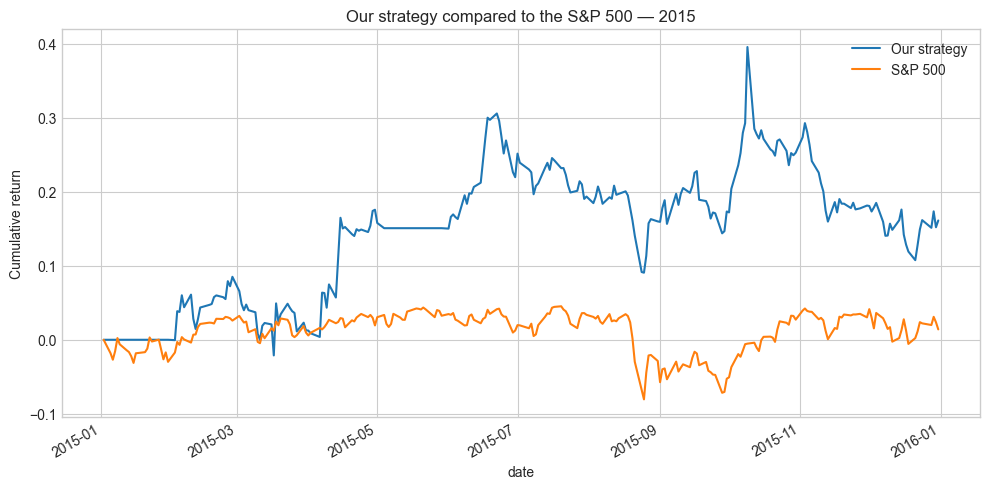

In [21]:
#We compare both portfolios over the same dates
comparison = history_2015[['nav']].copy()

sp500 = benchmark.set_index('date')['adj_close'].reindex(comparison.index)

if sp500.isna().any():
    raise ValueError("Some benchmark prices are missing.")

#We invest 1 million in the S&P 500 at the first test close
comparison['benchmark_nav'] = 1_000_000 * sp500 / sp500.iloc[0]

returns = comparison / 1_000_000 - 1
returns.columns = ['Our strategy', 'S&P 500']

returns.plot(figsize=(10, 5), title='Our strategy compared to the S&P 500 — 2015')
plt.ylabel('Cumulative return')
plt.tight_layout()
plt.show()

In [22]:
results = []

for name in ['nav', 'benchmark_nav']:
    values = comparison[name]
    daily_returns = values.pct_change(fill_method=None).dropna()

    years = (values.index[-1] - values.index[0]).days / 365.25
    final_value = values.iloc[-1]
    total_return = final_value / 1_000_000 - 1
    cagr = (final_value / 1_000_000) ** (1 / years) - 1

    drawdown = values / values.cummax() - 1
    max_drawdown = drawdown.min()

    daily_risk_free = 1.02 ** (1 / 252) - 1
    volatility = daily_returns.std()

    sharpe = np.nan
    if volatility > 0:
        sharpe = np.sqrt(252) * (daily_returns.mean() - daily_risk_free) / volatility

    results.append({'Portfolio': name, 'Final value': final_value, 'Return (%)': total_return * 100, 'CAGR (%)': cagr * 100, 'Max drawdown (%)': max_drawdown * 100, 'Sharpe': sharpe})

display(pd.DataFrame(results).set_index('Portfolio').round(3))

difference = (comparison['nav'].iloc[-1] - comparison['benchmark_nav'].iloc[-1]) / 1_000_000

print(f'Return difference against the S&P 500: {difference * 100:.2f} percentage points')

,Final value,Return (%),CAGR (%),Max drawdown (%),Sharpe
Portfolio,,,,,
nav,1161249.058,16.125,16.233,-20.642,0.627
benchmark_nav,1014042.052,1.404,1.413,-12.037,0.040


Return difference against the S&P 500: 14.72 percentage points


So with our method of investment in the year 2015, we got a better return than the benchmark strategy but with a higher maximum fall about 20% for our strategy against 12 percent for the benchmark strategy.

Even though our prediction model performs poorly, for the 2015 year it provides a useful ranking allowing us to get a return of 16.1 % for our strategy against 1.4% for the benchmark strategy, for the same amount of money.

In [23]:
#We run the backtest and get the trades
history_2015, lots_2015, trades_2015 = backtest_model(prices, calendar, predictions_2015, signal_dates_2015, membership, initial_cash=1_000_000, fee_rate=5 / 10_000, start_date=pd.Timestamp('2015-01-01'), end_date=pd.Timestamp('2015-12-31'))
buys = trades_2015.loc[trades_2015.side.eq('BUY')]
sales = trades_2015.loc[trades_2015.side.eq('SELL')]

#We rebuild the cash from the purchases and sales
cash_changes = trades_2015.groupby('date')['cash_change'].sum().reindex(history_2015.index, fill_value=0)
cash_check = 1_000_000 + cash_changes.cumsum()

assert np.allclose(history_2015['remaining_cash'], cash_check, rtol=0, atol=1e-6)

#We check that we never spend more cash than we have
assert (1_000_000 + trades_2015['cash_change'].cumsum() >= -1e-6).all()

#We check the portfolio value
assert np.allclose(history_2015['nav'], history_2015['remaining_cash'] + history_2015['holdings_value'], rtol=0, atol=1e-6)

#We check both fees
assert np.allclose(trades_2015['fee'], trades_2015['notional'] * (5 / 10_000))
assert np.isclose(trades_2015['fee'].sum(), history_2015['buy_fees'].sum() + history_2015['sell_fees'].sum())

#We check that we buy after the signal and sell after 90 days
assert buys['signal_date'].lt(buys['date']).all()
assert buys['due_date'].eq(buys['date'] + pd.Timedelta(days=90)).all()
assert sales['date'].ge(sales['due_date']).all()

#We check that each lot is bought and sold at most once
assert buys['lot_id'].is_unique
assert sales['lot_id'].is_unique
assert set(sales['lot_id']).issubset(set(buys['lot_id']))

for index, sale in sales.iterrows():
    purchase = buys.loc[buys.lot_id.eq(sale['lot_id'])].iloc[0]
    assert sale['symbol'] == purchase['symbol']
    assert np.isclose(sale['units'], purchase['units'])

#We check the remaining lots and total PnL
assert set(buys['lot_id']) - set(sales['lot_id']) == {lot['lot_id'] for lot in lots_2015}

unrealized_pnl = sum(lot['units'] * (lot['current_price'] - lot['entry_price']) - lot['buy_fee'] for lot in lots_2015)
assert np.isclose(history_2015.iloc[-1]['nav'] - 1_000_000, sales['realized_pnl'].sum() + unrealized_pnl, rtol=0, atol=1e-6)

display(trades_2015.head())

print('All these checks passed.')
print(f'Purchases: {len(buys)}, sales: {len(sales)}, open lots: {len(lots_2015)}')
print(f'Final NAV: {history_2015.iloc[-1]["nav"]:.2f}')
print(f'Total fees: {trades_2015["fee"].sum():.2f}')

,date,signal_date,lot_id,symbol,side,price,units,notional,fee,cash_change,due_date,realized_pnl
0,2015-02-02,2015-01-30,0,BESS,BUY,46.20,2909.994730,134441.756538,67.220878,-134508.977417,2015-05-03,0.0
1,2015-02-02,2015-01-30,1,APDN,BUY,1992000.00,0.063331,126154.854042,63.077427,-126217.931469,2015-05-03,0.0
2,2015-02-02,2015-01-30,2,FCX,BUY,15.81,7832.835238,123837.125109,61.918563,-123899.043672,2015-05-03,0.0
3,2015-02-02,2015-01-30,3,POZN,BUY,6.79,14828.632959,100686.417791,50.343209,-100736.760999,2015-05-03,0.0
4,2015-02-02,2015-01-30,4,MSFT,BUY,35.05,2539.184847,88998.428878,44.499214,-89042.928093,2015-05-03,0.0


All these checks passed.
Purchases: 70, sales: 60, open lots: 10
Final NAV: 1161249.06
Total fees: 3992.04


The accounting and timing checks above passed.
Our strategy also outperformed the benchmark in the 2015 development example.

Now let's check that this remains true with the full  homework dataset.

In [24]:
#We load the full homework data
database = modeling_dir / 'data/equities_top2000.duckdb'

prices_full, fundamentals_full, universe_full, benchmark_full = load_data(database, end='2026-09-30')
membership_full = load_membership(database, end='2026-09-30')

calendar_full = pd.DatetimeIndex(benchmark_full.date)

print(f'Number of stocks: {prices_full.symbol.nunique()}')
print(f'First date: {prices_full.date.min()}')
print(f'Last date: {prices_full.date.max()}')

C:\Users\theob\AppData\Local\Temp\ipykernel_20768\1706850700.py:4: UserWarning: Quarantining 275 invalid adjusted-price rows; inspect the raw database and delivery audit.
  prices_full, fundamentals_full, universe_full, benchmark_full = load_data(database, end='2026-09-30')


C:\Users\theob\AppData\Local\Temp\ipykernel_20768\1706850700.py:4: UserWarning: Quarantining 28 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
  prices_full, fundamentals_full, universe_full, benchmark_full = load_data(database, end='2026-09-30')


Number of stocks: 3849


First date: 2000-01-03 00:00:00
Last date: 2026-09-30 00:00:00


Now let's compute the same feature as there was on the previous dataset.

In [25]:
#We compute only the two features used by our model
features_full = ['momentum_63', 'volatility_63']
parts_full = []
membership_by_symbol = {symbol: group for symbol, group in membership_full.groupby('symbol')}

#The loading function already sorts prices by stock and date
symbols_full = prices_full['symbol'].to_numpy()
changes = np.flatnonzero(symbols_full[1:] != symbols_full[:-1]) + 1
starts = np.r_[0, changes]
ends = np.r_[changes, len(prices_full)]

#Membership depends on the quarter of the next trading day
next_quarters = calendar_full.to_series().shift(-1).dt.to_period('Q').dt.start_time.to_numpy()

for i in range(len(starts)):
    prices_symbol = prices_full.iloc[starts[i]:ends[i]][['symbol', 'date', 'adj_close']]
    symbol = prices_symbol['symbol'].iloc[0]
    adjusted_price = prices_symbol.set_index('date')['adj_close'].reindex(calendar_full)

    #These are the same formulas as the teacher's price_features function
    daily_returns = adjusted_price.pct_change(fill_method=None)
    momentum = adjusted_price.pct_change(63, fill_method=None)
    volatility = daily_returns.rolling(63, min_periods=63).std() * np.sqrt(252)

    membership_symbol = membership_by_symbol.get(symbol, membership_full.iloc[:0])
    selection_dates = membership_symbol.set_index('quarter_start')['selection_date'].reindex(next_quarters).to_numpy(dtype='datetime64[ns]')
    eligible = selection_dates <= calendar_full.to_numpy()

    panel_symbol = pd.DataFrame({'date': calendar_full, 'symbol': symbol, 'momentum_63': momentum.to_numpy(), 'volatility_63': volatility.to_numpy()})
    panel_symbol = panel_symbol.loc[eligible & panel_symbol.date.ge('2010-01-01')]
    panel_symbol = panel_symbol.replace([np.inf, -np.inf], np.nan).dropna(subset=features_full)

    #We check a few stocks against the original preprocessing
    if i in [0, 500, 1500, 3000]:
        expected = apply_membership(price_features(prices_symbol, calendar_full), membership_symbol, calendar_full)
        expected = expected.loc[expected.eligible & expected.date.ge('2010-01-01'), ['date', 'symbol'] + features_full]
        expected = expected.replace([np.inf, -np.inf], np.nan).dropna(subset=features_full)
        assert panel_symbol['date'].tolist() == expected['date'].tolist()
        assert np.allclose(panel_symbol[features_full], expected[features_full])

    parts_full.append(panel_symbol)

    if (i + 1) % 500 == 0:
        print(f'Stocks processed: {i + 1}', flush=True)

model_data_full = pd.concat(parts_full, ignore_index=True).sort_values(['date', 'symbol']).reset_index(drop=True)
del parts_full

assert not model_data_full.duplicated(['date', 'symbol']).any()
assert np.isfinite(model_data_full[features_full].to_numpy()).all()

print(f'Feature preparation complete: {len(model_data_full)} rows')
print(f'Stocks with eligible feature rows: {model_data_full.symbol.nunique()}')
display(model_data_full.head())


Stocks processed: 500


Stocks processed: 1000


Stocks processed: 1500


Stocks processed: 2000


Stocks processed: 2500


Stocks processed: 3000


Stocks processed: 3500


Feature preparation complete: 8322068 rows


Stocks with eligible feature rows: 3811


,date,symbol,momentum_63,volatility_63
0,2010-01-04,A,0.189904,0.241160
1,2010-01-04,AAIC,0.751112,0.594042
2,2010-01-04,AAL,0.106729,0.721282
3,2010-01-04,AAN,0.055008,0.293524
4,2010-01-04,AAON,0.061162,0.242896


Now that we have recomputed all the features for all the stocks, let's compute the 90 day returns between 2010 and 2015 (our targets)

In [26]:
#We use only development signal dates
fit_date_full = pd.Timestamp('2016-04-01')

train_full = model_data_full.loc[model_data_full.date.ge('2010-01-01') & model_data_full.date.lt('2016-01-01')].copy().reset_index(drop=True)
train_full['target'] = np.nan
train_full['label_end'] = pd.NaT

#We find each stock's rows in the sorted price table
symbols_full = prices_full['symbol'].to_numpy()
changes = np.flatnonzero(symbols_full[1:] != symbols_full[:-1]) + 1
starts = np.r_[0, changes]
ends = np.r_[changes, len(prices_full)]

price_ranges = {}

for i in range(len(starts)):
    symbol = prices_full['symbol'].iloc[starts[i]]
    price_ranges[symbol] = (starts[i], ends[i])

count = 0

for symbol, index in train_full.groupby('symbol', sort=False).indices.items():
    start, end = price_ranges[symbol]
    prices_symbol = prices_full.iloc[start:end].set_index('date')['adj_close']

    #We do not use any final-test prices to compute training outcomes
    prices_symbol = prices_symbol.loc[prices_symbol.index < fit_date_full]
    prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)]
    prices_symbol = prices_symbol.loc[prices_symbol.index.isin(calendar_full)].sort_index()

    if prices_symbol.empty:
        continue

    #We find the first available price after each signal
    entry_positions = prices_symbol.index.searchsorted(train_full.loc[index, 'date'], side='right')
    available = entry_positions < len(prices_symbol)

    index = index[available]
    entry_positions = entry_positions[available]

    entry_dates = prices_symbol.index[entry_positions]
    due_dates = entry_dates + pd.Timedelta(days=90)

    #We find the first available price on or after each due date
    exit_positions = prices_symbol.index.searchsorted(due_dates, side='left')
    available = exit_positions < len(prices_symbol)

    index = index[available]
    entry_positions = entry_positions[available]
    exit_positions = exit_positions[available]

    entry_prices = prices_symbol.iloc[entry_positions].to_numpy()
    exit_prices = prices_symbol.iloc[exit_positions].to_numpy()

    train_full.loc[index, 'target'] = exit_prices / entry_prices - 1
    train_full.loc[index, 'label_end'] = prices_symbol.index[exit_positions].to_numpy()

    count += 1
    if count % 500 == 0:
        print(f'Stocks processed: {count}', flush=True)

#We keep only outcomes completed before the final test
train_full = train_full.dropna(subset=features_full + ['target', 'label_end'])
train_full = train_full.loc[train_full.label_end.lt(fit_date_full)].copy()

assert train_full.date.lt('2016-01-01').all()
assert train_full.label_end.lt(fit_date_full).all()

print(f'Training rows: {len(train_full)}')
print(f'Last completed outcome: {train_full.label_end.max()}')
display(train_full.head())

Stocks processed: 500


Stocks processed: 1000


Stocks processed: 1500


Stocks processed: 2000


Training rows: 2967694
Last completed outcome: 2016-03-30 00:00:00


,date,symbol,momentum_63,volatility_63,target,label_end
0,2010-01-04,A,0.189904,0.241160,0.124553,2010-04-05
1,2010-01-04,AAIC,0.751112,0.594042,0.144010,2010-04-05
2,2010-01-04,AAL,0.106729,0.721282,0.342749,2010-04-05
3,2010-01-04,AAN,0.055008,0.293524,0.210394,2010-04-05
4,2010-01-04,AAON,0.061162,0.242896,0.193452,2010-04-05


In [27]:
#We keep the settings chosen during development
alpha_full = best_alpha
half_life_full = half_life

#We give more weight to recent training examples
age_full = (fit_date_full - train_full['date']).dt.days
weights_full = 0.5 ** (age_full / half_life_full)
weights_full = weights_full / weights_full.mean()

#We refit the same model on the full development data
model_full = make_pipeline(StandardScaler(), Ridge(alpha=alpha_full))
model_full.fit(train_full[features_full], train_full['target'], standardscaler__sample_weight=weights_full, ridge__sample_weight=weights_full)

print(f'Alpha: {alpha_full}')
print(f'Weight half-life: {half_life_full} calendar days')
print('Model fitted using outcomes known before April 1, 2016.')

Alpha: 100000
Weight half-life: 180 calendar days
Model fitted using outcomes known before April 1, 2016.


Now we generate our monthly predictions for the final test

In [28]:
#We take the last trading day of each month
signal_dates_full = []

for i in range(len(calendar_full) - 1):
    current_date = calendar_full[i]
    next_date = calendar_full[i + 1]

    if current_date.month != next_date.month:
        if current_date >= pd.Timestamp('2016-03-31') and next_date <= pd.Timestamp('2026-09-30'):
            signal_dates_full.append(current_date)

print(f'Number of signals: {len(signal_dates_full)}')
print(f'First signal: {signal_dates_full[0]}')
print(f'Last signal: {signal_dates_full[-1]}')

Number of signals: 126


First signal: 2016-03-31 00:00:00
Last signal: 2026-08-31 00:00:00


In [29]:
#We predict only on our monthly signal dates
predictions_full = model_data_full.loc[model_data_full.date.isin(signal_dates_full)].copy()

#We check that training outcomes were known before the first decision
assert train_full['label_end'].max() < predictions_full['date'].min()

predictions_full['prediction'] = model_full.predict(predictions_full[features_full])

assert np.isfinite(predictions_full['prediction']).all()

display(predictions_full[['date', 'symbol', 'prediction']].head())
print(f'Number of predictions: {len(predictions_full)}')

,date,symbol,prediction
3089560,2016-03-31,A,-0.017168
3089561,2016-03-31,AAIC,-0.015647
3089562,2016-03-31,AAL,-0.016957
3089563,2016-03-31,AAM,-0.008365
3089564,2016-03-31,AAN,-0.001429


Number of predictions: 249796


Now let's build our final strategy on the full dataset and let's observe the performance of our model on the final test period. We will analyze the cumulative returns, compare it to the S&P 500 benchmark, and evaluate key performance metrics such as CAGR, maximum drawdown, and Sharpe ratio.

In [30]:
def backtest_model_full(prices, calendar, predictions, signal_dates, membership, initial_cash, fee_rate, start_date, end_date):

    if not np.isfinite(initial_cash) or initial_cash <= 0:
        raise ValueError("Initial cash must be positive.")

    if not np.isfinite(fee_rate) or fee_rate < 0:
        raise ValueError("Fee rate must be non-negative.")

    cash = initial_cash
    lots = []
    pending_buys = []
    navs = []
    trades = []
    lot_id = 0

    #We find which stocks can be selected so we only store their prices
    selected_symbols = set()

    for signal_date, group in predictions.groupby('date'):
        group = group.loc[np.isfinite(group.prediction) & group.prediction.gt(0)]
        group = group.sort_values('prediction', ascending=False).head(10)
        selected_symbols.update(group['symbol'])

    #The loading function already sorts prices by stock and date
    symbols = prices['symbol'].to_numpy()
    changes = np.flatnonzero(symbols[1:] != symbols[:-1]) + 1
    starts = np.r_[0, changes]
    ends = np.r_[changes, len(prices)]

    prices_by_symbol = {}

    for i in range(len(starts)):
        symbol = symbols[starts[i]]

        if symbol in selected_symbols:
            prices_symbol = prices.iloc[starts[i]:ends[i]][['date', 'adj_close']].set_index('date')['adj_close']
            prices_symbol = prices_symbol.loc[np.isfinite(prices_symbol) & (prices_symbol > 0)]
            prices_by_symbol[symbol] = prices_symbol

    #We find the buying date after each signal
    buy_dates = {}

    for signal_date in signal_dates:
        if calendar.searchsorted(signal_date, side='right') >= len(calendar):
            raise ValueError("No entry date available.")

        entry_date = calendar[calendar.searchsorted(signal_date, side='right')]
        buy_dates[entry_date] = signal_date

    for current_date in calendar[(calendar >= start_date) & (calendar <= end_date)]:
        buy_fees = 0
        sell_fees = 0
        stale_marks = 0

        #We check which stocks are eligible for today's purchases
        quarter_start = current_date.to_period('Q').start_time
        eligible_symbols = membership.loc[membership.quarter_start.eq(quarter_start) & membership.selection_date.lt(current_date), 'symbol']

        #We do not allocate cash already reserved for another purchase
        if current_date in buy_dates:
            reserved_cash = sum(order['budget'] for order in pending_buys)
            available_cash = max(0, cash - reserved_cash)

            orders = allocate_cash(predictions, buy_dates[current_date], available_cash)
            orders = orders.loc[orders.budget > 0]

            for index, order in orders.iterrows():
                pending_buys.append({'symbol': order['symbol'], 'budget': order['budget'], 'signal_date': buy_dates[current_date]})

        #We buy before selling so today's sales fund later purchases
        for order in pending_buys.copy():
            symbol = order['symbol']
            budget = order['budget']
            prices_symbol = prices_by_symbol[symbol]

            if symbol not in eligible_symbols.values:
                pending_buys.remove(order)
                continue

            #If there is no price we wait for another day
            if current_date not in prices_symbol.index:
                continue

            if budget > cash + 1e-8:
                pending_buys.remove(order)
                continue

            budget = min(budget, cash)

            if budget <= 0:
                pending_buys.remove(order)
                continue

            entry_price = prices_symbol.loc[current_date]
            units, buy_fee, cash = buy(cash, budget, entry_price, fee_rate)

            lots.append({'lot_id': lot_id, 'symbol': symbol, 'signal_date': order['signal_date'], 'units': units, 'entry_price': entry_price, 'entry_date': current_date, 'due_date': current_date + pd.Timedelta(days=90), 'buy_fee': buy_fee, 'current_price': entry_price})

            trades.append({'date': current_date, 'signal_date': order['signal_date'], 'lot_id': lot_id, 'symbol': symbol, 'side': 'BUY', 'price': entry_price, 'units': units, 'notional': units * entry_price, 'fee': buy_fee, 'cash_change': -units * entry_price - buy_fee, 'due_date': current_date + pd.Timedelta(days=90), 'realized_pnl': 0})

            lot_id += 1
            buy_fees += buy_fee
            pending_buys.remove(order)

        #We sell the lots that have reached their due date
        for lot in lots.copy():
            prices_symbol = prices_by_symbol[lot['symbol']]

            if current_date >= lot['due_date']:
                if current_date not in prices_symbol.index:
                    continue

                sell_price = prices_symbol.loc[current_date]
                cash, sell_fee = sell(lot['units'], sell_price, cash, fee_rate)

                realized_pnl = lot['units'] * (sell_price - lot['entry_price']) - lot['buy_fee'] - sell_fee

                trades.append({'date': current_date, 'signal_date': lot['signal_date'], 'lot_id': lot['lot_id'], 'symbol': lot['symbol'], 'side': 'SELL', 'price': sell_price, 'units': lot['units'], 'notional': lot['units'] * sell_price, 'fee': sell_fee, 'cash_change': lot['units'] * sell_price - sell_fee, 'due_date': lot['due_date'], 'realized_pnl': realized_pnl})

                sell_fees += sell_fee
                lots.remove(lot)

        #We compute the value of the lots we still own
        total_holdings_value = 0

        for lot in lots:
            prices_symbol = prices_by_symbol[lot['symbol']]

            if current_date in prices_symbol.index:
                lot['current_price'] = prices_symbol.loc[current_date]
            else:
                #Otherwise we keep the last known price
                stale_marks += 1

            holdings_value = lot['units'] * lot['current_price']
            total_holdings_value += holdings_value

        nav = cash + total_holdings_value
        navs.append({'date': current_date, 'nav': nav, 'holdings_value': total_holdings_value, 'remaining_cash': cash, 'buy_fees': buy_fees, 'sell_fees': sell_fees, 'open_lots': len(lots), 'stale_marks': stale_marks})

    if not navs:
        raise ValueError("No trading dates available in this period.")

    history = pd.DataFrame(navs).set_index('date')
    trades = pd.DataFrame(trades, columns=['date', 'signal_date', 'lot_id', 'symbol', 'side', 'price', 'units', 'notional', 'fee', 'cash_change', 'due_date', 'realized_pnl'])

    return history, lots, trades


#We run the final test with our fixed model and strategy
history_full, lots_full, trades_full = backtest_model_full(prices_full, calendar_full, predictions_full, signal_dates_full, membership_full, initial_cash=1_000_000, fee_rate=5 / 10_000, start_date=pd.Timestamp('2016-04-01'), end_date=pd.Timestamp('2026-09-30'))

#We check the portfolio value and rebuild the cash
assert np.allclose(history_full['nav'], history_full['remaining_cash'] + history_full['holdings_value'], rtol=0, atol=1e-6)
assert (history_full['remaining_cash'] >= -1e-8).all()

cash_changes = trades_full.groupby('date')['cash_change'].sum().reindex(history_full.index, fill_value=0)
assert np.allclose(history_full['remaining_cash'], 1_000_000 + cash_changes.cumsum(), rtol=0, atol=1e-6)

display(history_full)
display(pd.DataFrame(lots_full))
display(trades_full.head())

print(f'Final NAV: {history_full.iloc[-1]["nav"]:.2f}')
print(f'Total fees: {trades_full["fee"].sum():.2f}')
print(f'Days with missing held prices: {(history_full["stale_marks"] > 0).sum()}')

,nav,holdings_value,remaining_cash,buy_fees,sell_fees,open_lots,stale_marks
date,,,,,,,
2016-04-01,9.995002e+05,9.995002e+05,9.458745e-11,499.750125,0.000000,10,0
2016-04-04,9.904860e+05,9.904860e+05,9.458745e-11,0.000000,0.000000,10,0
2016-04-05,1.011749e+06,1.011749e+06,9.458745e-11,0.000000,0.000000,10,0
2016-04-06,1.022818e+06,1.022818e+06,9.458745e-11,0.000000,0.000000,10,0
2016-04-07,1.074930e+06,1.074930e+06,9.458745e-11,0.000000,0.000000,10,0
...,...,...,...,...,...,...,...
2026-09-24,7.374541e+05,7.374541e+05,3.226995e-14,0.000000,0.000000,56,28
2026-09-25,7.441035e+05,7.441035e+05,3.226995e-14,0.000000,0.000000,56,28
2026-09-28,7.383431e+05,7.383431e+05,3.226995e-14,0.000000,0.000000,56,28


,lot_id,symbol,signal_date,units,entry_price,entry_date,due_date,buy_fee,current_price
0,36,DWRE,2016-06-30,1.206321e+03,74.990000,2016-07-01,2016-09-29,4.523102e+01,74.970
1,601,ARNA,2022-01-31,3.097029e-13,92.700000,2022-02-01,2022-05-02,1.435473e-14,99.990
2,607,VCRA,2022-01-31,2.100710e-13,78.900000,2022-02-01,2022-05-02,8.287301e-15,79.130
3,614,ARNA,2022-02-28,9.633300e-30,94.690000,2022-03-01,2022-05-30,4.560886e-31,99.990
4,650,TPTX,2022-06-30,5.869766e-13,75.110000,2022-07-01,2022-09-29,2.204390e-14,76.010
5,660,GBT,2022-08-31,2.100096e+03,68.150000,2022-09-01,2022-11-30,7.156076e+01,68.490
6,678,GBT,2022-09-30,5.846213e-14,68.480000,2022-10-03,2023-01-01,2.001743e-15,68.490
7,685,POSH,2022-11-30,2.056940e+03,17.820000,2022-12-01,2023-03-01,1.832733e+01,17.900
8,694,IMGO,2022-12-30,3.052927e-13,35.980000,2023-01-03,2023-04-03,5.492216e-15,36.010
9,698,USER,2022-12-30,9.243307e-13,7.500000,2023-01-03,2023-04-03,3.466240e-15,7.500


,date,signal_date,lot_id,symbol,side,price,units,notional,fee,cash_change,due_date,realized_pnl
0,2016-04-01,2016-03-31,0,SKY,BUY,8.538767e+00,29511.328776,251990.356174,125.995178,-252116.351352,2016-06-30,0.0
1,2016-04-01,2016-03-31,1,CDE,BUY,5.633674e+00,23807.444813,134123.374941,67.061687,-134190.436628,2016-06-30,0.0
2,2016-04-01,2016-03-31,2,X,BUY,1.555000e+01,6532.520075,101580.687166,50.790344,-101631.477510,2016-06-30,0.0
3,2016-04-01,2016-03-31,3,SXC,BUY,4.920000e+00,16884.329819,83070.902707,41.535451,-83112.438158,2016-06-30,0.0
4,2016-04-01,2016-03-31,4,CEI,BUY,1.191406e+08,0.000675,80398.239704,40.199120,-80438.438824,2016-06-30,0.0


Final NAV: 742878.72
Total fees: 39604.45
Days with missing held prices: 2571


In [31]:
#We inspect the positions with missing prices or overdue sales
missing_positions = []
end_date = history_full.index[-1]

for lot in lots_full:
    start, end = price_ranges[lot['symbol']]
    prices_symbol = prices_full.iloc[start:end]

    prices_symbol = prices_symbol.loc[prices_symbol.date.le(end_date) & np.isfinite(prices_symbol.adj_close) & prices_symbol.adj_close.gt(0)]
    last_price_date = prices_symbol['date'].max()

    if last_price_date < end_date or lot['due_date'] <= end_date:
        missing_positions.append({'symbol': lot['symbol'], 'entry_date': lot['entry_date'], 'due_date': lot['due_date'], 'last_price_date': last_price_date, 'days_without_price': (end_date - last_price_date).days, 'carried_value': lot['units'] * lot['current_price']})

missing_positions = pd.DataFrame(missing_positions, columns=['symbol', 'entry_date', 'due_date', 'last_price_date', 'days_without_price', 'carried_value'])

if missing_positions.empty:
    print('No unresolved positions found.')
else:
    display(missing_positions.sort_values('carried_value', ascending=False))
    print(f'Total carried value: {missing_positions["carried_value"].sum():.2f}')

,symbol,entry_date,due_date,last_price_date,days_without_price,carried_value
5,GBT,2022-09-01,2022-11-30,2022-10-04,1457,1.438356e+05
0,DWRE,2016-07-01,2016-09-29,2016-07-08,3736,9.043791e+04
12,PRVB,2023-04-03,2023-07-02,2023-04-27,1252,5.939563e+04
24,BSGM,2025-08-01,2025-10-30,2025-09-11,384,4.740285e+04
17,DWAC,2024-02-01,2024-05-01,2024-03-25,919,4.510098e+04
15,MRTX,2023-11-01,2024-01-30,2024-01-23,981,3.686803e+04
7,POSH,2022-12-01,2023-03-01,2023-01-04,1365,3.681922e+04
26,CIFRW,2025-11-03,2026-02-01,2025-12-26,278,2.686771e+04
27,CRNX,2026-08-03,2026-11-01,2026-08-31,30,2.900014e+02
16,IMGN,2023-12-01,2024-02-29,2024-02-13,960,3.177826e+00


Total carried value: 487021.08


In [32]:
#We flag positions whose last price is more than 5 trading sessions old
gap_report = missing_positions.copy()

gap_report['missing_sessions'] = gap_report['last_price_date'].apply(lambda date: ((calendar_full > date) & (calendar_full <= history_full.index[-1])).sum())

gap_report = gap_report.loc[gap_report.missing_sessions > 5]

display(gap_report.sort_values('carried_value', ascending=False))

print(f'Positions with unresolved price gaps: {len(gap_report)}')
print(f'Value carried at old prices: ${gap_report["carried_value"].sum():,.2f}')

if not gap_report.empty:
    print('The final performance is provisional because some positions cannot be valued or exited reliably.')

,symbol,entry_date,due_date,last_price_date,days_without_price,carried_value,missing_sessions
5,GBT,2022-09-01,2022-11-30,2022-10-04,1457,1.438356e+05,1000
0,DWRE,2016-07-01,2016-09-29,2016-07-08,3736,9.043791e+04,2571
12,PRVB,2023-04-03,2023-07-02,2023-04-27,1252,5.939563e+04,859
24,BSGM,2025-08-01,2025-10-30,2025-09-11,384,4.740285e+04,264
17,DWAC,2024-02-01,2024-05-01,2024-03-25,919,4.510098e+04,631
15,MRTX,2023-11-01,2024-01-30,2024-01-23,981,3.686803e+04,674
7,POSH,2022-12-01,2023-03-01,2023-01-04,1365,3.681922e+04,937
26,CIFRW,2025-11-03,2026-02-01,2025-12-26,278,2.686771e+04,190
27,CRNX,2026-08-03,2026-11-01,2026-08-31,30,2.900014e+02,21
16,IMGN,2023-12-01,2024-02-29,2024-02-13,960,3.177826e+00,659


Positions with unresolved price gaps: 28
Value carried at old prices: $487,021.08
The final performance is provisional because some positions cannot be valued or exited reliably.


We observe missing prices.

Here we have an issue for $487,021.08 of positions, and these positions
are still valued at the old price. Now let's understand why those stocks
stopped trading under these tickers.

After some research, we see that companies like DWRE or GBT were acquired.
Our backtest does not handle the cash payments or other changes linked
to these acquisitions.

For other stocks like BSGM or DWAC, there were ticker changes. For example,
DJT prices exist in the database, but our code does not connect our DWAC
position to this new ticker. Other price histories are missing.

Consequently, the full-period result is an incomplete simulation which
does not allow us to make a reliable claim about the exact final performance.

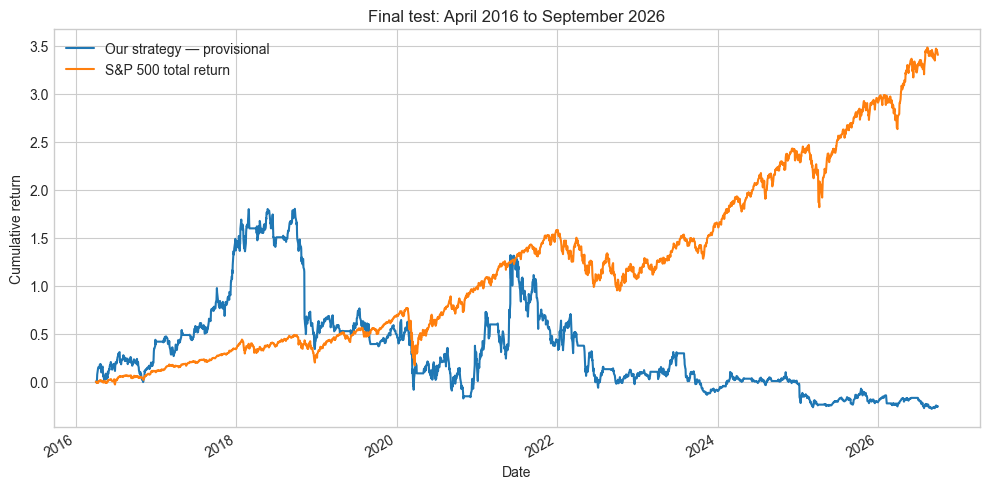

Our strategy uses old prices for unresolved positions. Its performance remains provisional.


In [33]:
#We compare both portfolios over the same final-test dates
initial_cash = 1_000_000

comparison_full = history_full[['nav']].copy()
sp500_full = benchmark_full.set_index('date')['adj_close'].reindex(comparison_full.index)

if sp500_full.isna().any():
    raise ValueError("Some benchmark prices are missing.")

#We invest in the S&P 500 at the first test close
comparison_full['benchmark_nav'] = initial_cash * sp500_full / sp500_full.iloc[0]

returns_full = comparison_full / initial_cash - 1
returns_full.columns = ['Our strategy — provisional', 'S&P 500 total return']

returns_full.plot(figsize=(10, 5), title='Final test: April 2016 to September 2026')
plt.ylabel('Cumulative return')
plt.xlabel('Date')
plt.tight_layout()
plt.show()

print('Our strategy uses old prices for unresolved positions. Its performance remains provisional.')

In [34]:
results_full = []

for name in ['nav', 'benchmark_nav']:
    values = comparison_full[name]

    #We include the first day's change from our initial capital
    daily_returns = values.pct_change(fill_method=None)
    daily_returns.iloc[0] = values.iloc[0] / initial_cash - 1

    years = (values.index[-1] - values.index[0]).days / 365.25
    final_value = values.iloc[-1]
    total_return = final_value / initial_cash - 1
    cagr = (final_value / initial_cash) ** (1 / years) - 1

    #We include initial capital when finding the previous peak
    previous_peak = values.cummax().clip(lower=initial_cash)
    drawdown = values / previous_peak - 1
    max_drawdown = drawdown.min()

    daily_risk_free = 1.02 ** (1 / 252) - 1
    volatility = daily_returns.std()

    sharpe = np.nan
    if volatility > 0:
        sharpe = np.sqrt(252) * (daily_returns.mean() - daily_risk_free) / volatility

    portfolio = 'Our strategy' if name == 'nav' else 'S&P 500 total return'

    results_full.append({'Portfolio': portfolio, 'Final value ($)': final_value, 'Return (%)': total_return * 100, 'CAGR (%)': cagr * 100, 'Max drawdown (%)': max_drawdown * 100, 'Sharpe': sharpe})

display(pd.DataFrame(results_full).set_index('Portfolio').round(3))

difference = (comparison_full['nav'].iloc[-1] - comparison_full['benchmark_nav'].iloc[-1]) / initial_cash

print(f'Provisional return difference against the S&P 500: {difference * 100:.2f} percentage points')
#We bound the effect of the positions valued at old prices
stale_value = gap_report['carried_value'].sum()
nav_without_stale = comparison_full['nav'].iloc[-1] - stale_value
multiple_needed = (comparison_full['benchmark_nav'].iloc[-1] - nav_without_stale) / stale_value
print(f'If the positions valued at old prices were worth nothing, our final value would be ${nav_without_stale:,.2f}.')
print(f'To match the S&P 500, they would need to be worth {multiple_needed:.1f} times their old prices, so we did not beat the benchmark.')

,Final value ($),Return (%),CAGR (%),Max drawdown (%),Sharpe
Portfolio,,,,,
Our strategy,742878.717,-25.712,-2.792,-74.421,0.069
S&P 500 total return,4402746.776,340.275,15.166,-33.790,0.773


Provisional return difference against the S&P 500: -365.99 percentage points
If the positions valued at old prices were worth nothing, our final value would be $255,857.64.
To match the S&P 500, they would need to be worth 8.5 times their old prices, so we did not beat the benchmark.


### Our model and strategy

We want to predict the return of a stock over 90 calendar days. For that we use
two features: the momentum over the last 63 trading days and the volatility
over the same period.

We start with Ridge regression because it is a simple model, with a penalty
that limits the size of the coefficients. We choose alpha using the MSE on
the 2013 validation set. We only train with returns already known before 2013.
Then we check the chosen model on 2015.

We also give more weight to recent training examples. An example 180 calendar
days older gets half as much weight.

For the final test, we train again using the full dataset. We keep signal dates
between 2010 and 2015 and only use returns completed before April 1, 2016.
We keep the same alpha and exponential weighting rule.

We do not update the model during the final test. Retraining is optional in
the assignment. We still make new predictions each month using the latest
features, but the fitted model stays the same.

### How we invest

At the end of each month, we take the ten stocks with the highest positive
predicted returns. If fewer than ten have a positive prediction, we take fewer.

We allocate the available cash in proportion to each stock's predicted return.
We buy at the next trading day's close. If the price is missing, we wait for
an available price and check that the stock is still eligible.

Here eligible means that the stock belongs to the supplied universe for the
quarter of the actual purchase. If a pending purchase is no longer eligible,
we cancel it. If we already own the stock, leaving the universe does not force
us to sell it.

We hold each purchase for 90 calendar days. If we cannot sell on the due date,
we wait for an available price.

We start with $1 million. We do not short stocks or borrow money.
We allow fractional adjusted-price units and pay a fee of 0.05% when buying
and selling. Cash earns no interest. We use adjusted prices, so we do not
add dividends again.

### Missing prices

If a purchase never gets an available price, it remains pending unless it is
cancelled because the stock is no longer eligible. No cash is spent before
the purchase happens.

If we already own the stock and its price never returns, our simulation keeps
the position at its last known price. Our diagnostic flags final positions
whose prices are more than five trading sessions old. This does not establish
that we could sell them or recover that value.

We do not remove stocks because we know their prices will disappear during
the following 90 days. That would use information unavailable when investing.

Some missing histories are linked to acquisitions or ticker changes.
Our backtester does not fully handle these corporate events. For example,
DJT prices exist in the database, but our code does not transfer an existing
DWAC position to its successor. Other successor histories are missing.

Consequently, the full-period result is an incomplete simulation. Its accounting
reconciles, but unresolved price gaps prevent us from claiming reliable final
performance. We do not invent sales or assume zero recovery.

### What we observe

Our Ridge model does not improve prediction errors much compared to always
predicting the weighted average training return.

However, in the 2015 development example, our strategy beats the S&P 500
by 14.72 percentage points. It also has a larger maximum drawdown.
This one result does not prove that the predictions are accurate or that
the strategy will keep working but shows that without missing data in 2015 
our strategy outperforms the benchmark strategy.

On the full dataset, the simulation reports a loss, but substantial holdings
are valued using old prices. We therefore cannot interpret this as a reliable
measurement of the strategy's actual final performance.
However, even if these holdings were worth nothing or eight times their old prices, our strategy would
stay below the S&P 500. So we did not beat the benchmark: our provisional final value is about
$3.66 million below it.

Buying up to ten stocks each month and allocating according to predictions
can concentrate the portfolio. 


### What we could try next

First, we would improve the handling of missing prices, ticker changes and
corporate actions using verified data.
We could also screen out warrants and SPACs, such as CIFRW or DWAC, using
information available at the time.

We could also try other features or a more flexible prediction model, such as
a multilayer perceptron. A more complex model would not automatically produce
better predictions and would not solve missing-price problems.

These changes would need chronological validation using development data.
We would not choose them simply because they improve the final-test result
that we have already observed.

### Code and assistance

We reuse the teacher's data-loading and preprocessing code, we also reused
the backtester accounting to check that our computations were working before
implementing our full backtester.

AI assistance was used to help plan the work and break the backtester into
smaller steps. It guided me through short exercises and question-and-answer
explanations so I could understand each part before moving to the next one.

AI also helped with code suggestions, debugging, accounting checks,
investigating the missing prices and a final review of this notebook.